# Practical Session 10 &mdash; C. Crowds, trees, and choosing

Clouds can stretch and tilt, but they cannot **bend**. This notebook takes two other ideas of a group: a
**crowd**, a crowded region of any shape (DBSCAN), and a **branch** of a tree of merges (hierarchical
clustering). Then it puts all the methods side by side, situation by situation, and ends with what to use when.

| | Notebook | What you do |
|---|---|---|
| A | k-means, and what can go wrong | k-means by hand, a photo, bad starts, scoring by counting pairs, units |
| B | How many groups, and clouds | the elbow and the silhouette; Gaussian mixtures and soft memberships |
| **C** | **Crowds, trees, and choosing** | **DBSCAN and hierarchical clustering by hand; which method for which situation (this notebook)** |

> &#11088; **Key idea.** Crowds and trees find shapes that centers cannot, but each has a knob that sets how many
> groups you get, and no method wins in every situation.

The data: two moons, two rings, the ten points, the rents of eight apartments, round blobs, tilted clouds, a
small group beside a big one, and 178 wines (real data). As before, the true groups are used only to score.

*Run the cells in order (Shift+Enter). Self-contained and offline; the whole notebook runs in about
35 seconds (the comparison of &sect;9 takes about 15 of them).*

In [1]:
import itertools

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans, SpectralClustering
from sklearn.datasets import load_wine, make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from nb_utils import use_style
from nb_data import make_rent8, make_shapes, make_ten_points

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP = "#CC79A7"                   # pink, when a fifth color is needed
CX = "0.62"                      # gray, for reference lines and noise
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette
COLORS = [C0, C1, CG, CN, CP]


def show_groups(ax, X, labels, title, s=8):
    "points colored by group; label -1 (noise) as small gray crosses"
    many = COLORS if len(set(labels) - {-1}) <= len(COLORS) else \
        [c for i, c in enumerate(plt.get_cmap("tab20").colors) if i not in (14, 15)]   # > 5 clusters: 18 colors, no gray
    for k in sorted(set(labels)):
        P = X[labels == k]
        if k == -1:
            ax.scatter(*P.T, s=s * 2, marker="x", color=CX, linewidth=1)
        else:
            ax.scatter(*P.T, s=s, color=many[k % len(many)])
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")


def n_groups(labels):
    "the number of clusters, not counting noise (-1)"
    return len(set(labels) - {-1})


def ari(truth, labels):
    "the ARI, printed as 0.00 rather than -0.00 when it is that close to zero"
    score = adjusted_rand_score(truth, labels)
    return 0.0 if abs(score) < 0.005 else score


shapes = make_shapes()
Xm, ym = shapes["two moons"]
Xr, yr = shapes["two rings"]
print("ready")

ready


## 1. Clouds cannot bend

A mixture's clouds can stretch and tilt. Can they follow two moons, or a ring inside a ring?

two moons: k-means ARI 0.23, mixture ARI 0.46
two rings: k-means ARI 0.00, mixture ARI 0.00


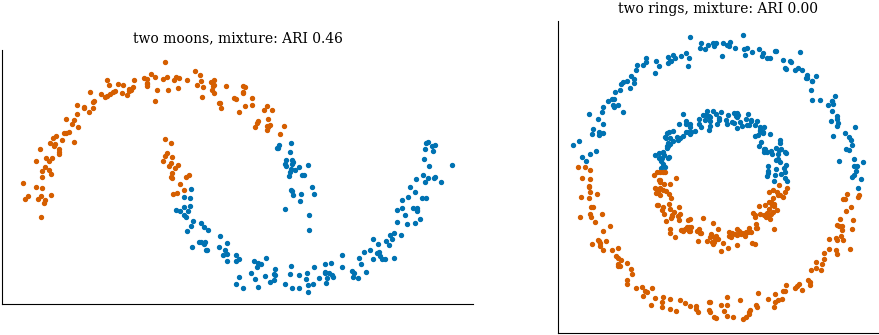

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
for ax, (name, (X, y)) in zip(axes, (("two moons", (Xm, ym)), ("two rings", (Xr, yr)))):
    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
    gm = GaussianMixture(n_components=2, covariance_type="full", n_init=10, random_state=0).fit_predict(X)
    print(f"{name}: k-means ARI {ari(y, km):.2f}, mixture ARI {ari(y, gm):.2f}")
    show_groups(ax, X, gm, f"{name}, mixture: ARI {ari(y, gm):.2f}")
plt.show()

Clouds can stretch, but they cannot bend: on the moons a mixture scores 0.46 (k-means 0.23), on the rings 0.00.
For crescents and rings we need another idea of a group: a **crowd**. From a drone over a festival you see
crowds, not centers: a crowd is wherever people stand close together, whatever its shape, and the lone walkers
in between belong to none.

## 2. DBSCAN: clusters are crowded regions

Pick a radius $\varepsilon$ (eps) and a number minPts.

* A **core** point has at least minPts points within $\varepsilon$, itself included (minPts = 3: "me and two
  others"). Core points within $\varepsilon$ of each other join one cluster, which grows like a chain.
* A **border** point is not crowded itself, but within $\varepsilon$ of a core point: it joins that cluster.
* A **noise** point is neither: it belongs to no cluster.

No $K$ to choose: the number of clusters comes out of the data (and out of $\varepsilon$). By hand, on the ten
points, with $\varepsilon = 3.2$ and minPts = 3. Integer coordinates mean integer **squared** distances, so we
compare them with $3.2^2 = 10.24$: 10 is in, 13 is out. The cell prints every point's count of neighbors
(itself included) and its neighbors, and draws a circle of radius $\varepsilon$ around P1, P4 and P10. The
markers show the ten points' own classes (round P1 to P5, square P6 to P10), which DBSCAN never sees.

**Your turn (2 minutes):** run the cell, then check the rows of P1, P4 and P10 on the picture.

eps = 3.2 (squared: 10.24), minPts = 3
point count   neighbors (squared distance)
P1        2   P2 (10)
P2        2   P1 (10)
P3        3   P6 (2), P7 (5)
P4        4   P5 (8), P8 (10), P9 (10)
P5        4   P8 (2), P4 (8), P9 (10)
P6        3   P3 (2), P7 (5)
P7        3   P3 (5), P6 (5)
P8        3   P5 (2), P4 (10)
P9        4   P10 (2), P4 (10), P5 (10)
P10       2   P9 (2)


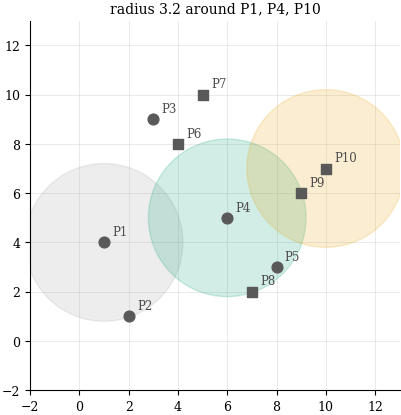

In [3]:
X10, y10 = make_ten_points()
NAMES = [f"P{i}" for i in range(1, 11)]
EPS, MIN_PTS = 3.2, 3                                # <-- CHANGE ME: the two knobs
d2 = ((X10[:, None, :] - X10[None, :, :]) ** 2).sum(axis=2)      # squared distances
print(f"eps = {EPS:g} (squared: {EPS ** 2:g}), minPts = {MIN_PTS}")
print(f"{'point':6s}{'count':>5s}   neighbors (squared distance)")
for i in range(len(X10)):
    nb = sorted((d2[i, j], j) for j in range(len(X10)) if j != i and d2[i, j] <= EPS ** 2)
    print(f"{NAMES[i]:6s}{1 + len(nb):5d}   {', '.join(f'{NAMES[j]} ({d:g})' for d, j in nb)}")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
for cls, marker in ((0, "o"), (1, "s")):             # the ten points' own classes: circles and squares
    ax.scatter(*X10[y10 == cls].T, s=60, color="0.35", marker=marker, zorder=3)
for i, (a, b) in enumerate(X10):
    ax.annotate(NAMES[i], (a, b), (6, 5), textcoords="offset points", fontsize=8.5, color="0.3")
for i, c in ((0, CX), (3, CG), (9, CN)):             # circles of radius eps around P1, P4, P10
    ax.add_patch(plt.Circle(X10[i], EPS, color=c, alpha=0.18))
ax.set_xlim(-2, 13); ax.set_ylim(-2, 13); ax.set_aspect("equal")
ax.set_title(f"radius {EPS:g} around P1, P4, P10", fontsize=10)
plt.show()

**Predict first:** P1 and P2 are neighbors. Are they a cluster?

The function below writes DBSCAN out: count the neighbors, mark the core points, grow a cluster from each core
point. It prints the table again, now with each point's role.

eps = 3.2 (squared: 10.24), minPts = 3
point count  role    neighbors (squared distance)
P1        2  noise   P2 (10)
P2        2  noise   P1 (10)
P3        3  core    P6 (2), P7 (5)
P4        4  core    P5 (8), P8 (10), P9 (10)
P5        4  core    P8 (2), P4 (8), P9 (10)
P6        3  core    P3 (2), P7 (5)
P7        3  core    P3 (5), P6 (5)
P8        3  core    P5 (2), P4 (10)
P9        4  core    P10 (2), P4 (10), P5 (10)
P10       2  border  P9 (2)
cluster 1: ['P3', 'P6', 'P7']
cluster 2: ['P4', 'P5', 'P8', 'P9', 'P10']
noise: ['P1', 'P2']
scikit-learn's DBSCAN gives the same groups: True
against the ten points' own classes (P1-P5 against P6-P10): ARI -0.02


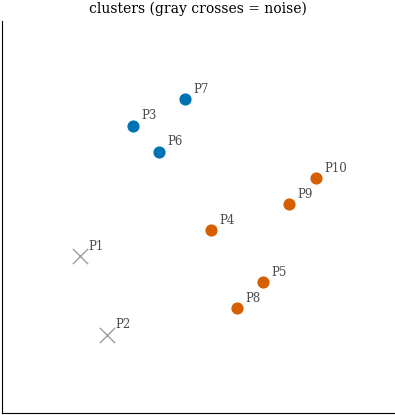

In [4]:
def dbscan_by_hand(X, eps, min_pts, show=True):
    '''DBSCAN written out. Returns one label per point (-1 = noise) and which points are core.'''
    d2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2)          # squared distances
    near = d2 <= eps ** 2                                            # neighbors, the point itself included
    core = near.sum(axis=1) >= min_pts
    label = np.full(len(X), -1)
    k = 0
    for i in np.flatnonzero(core):                                   # grow a cluster from each new core point
        if label[i] != -1:
            continue
        label[i], todo = k, [i]
        while todo:                                                  # the chain: core points pass it on
            j = todo.pop()
            for m in np.flatnonzero(near[j]):
                if label[m] == -1:
                    label[m] = k
                    if core[m]:
                        todo.append(m)
        k += 1
    if show:
        print(f"eps = {eps:g} (squared: {eps ** 2:g}), minPts = {min_pts}")
        print(f"{'point':6s}{'count':>5s}  {'role':8s}neighbors (squared distance)")
        for i in range(len(X)):
            nb = sorted((d2[i, j], j) for j in range(len(X)) if j != i and near[i, j])
            role = "core" if core[i] else ("border" if label[i] >= 0 else "noise")
            print(f"{NAMES[i]:6s}{1 + len(nb):5d}  {role:8s}{', '.join(f'{NAMES[j]} ({d:g})' for d, j in nb)}")
    return label, core


lab10, core10 = dbscan_by_hand(X10, EPS, MIN_PTS)
for k in range(n_groups(lab10)):
    print(f"cluster {k + 1}: {[NAMES[i] for i in np.flatnonzero(lab10 == k)]}")
print(f"noise: {[NAMES[i] for i in np.flatnonzero(lab10 == -1)]}")
sk = DBSCAN(eps=EPS, min_samples=MIN_PTS).fit_predict(X10)
print(f"scikit-learn's DBSCAN gives the same groups: {adjusted_rand_score(lab10, sk) == 1.0}")
print(f"against the ten points' own classes (P1-P5 against P6-P10): ARI {adjusted_rand_score(y10, lab10):.2f}")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
for i, (a, b) in enumerate(X10):
    ax.annotate(NAMES[i], (a, b), (6, 5), textcoords="offset points", fontsize=8.5, color="0.3")
show_groups(ax, X10, lab10, "clusters (gray crosses = noise)", s=60)
ax.set_xlim(-2, 13); ax.set_ylim(-2, 13)
plt.show()

P1 and P2 are neighbors (squared distance 10), but **a pair is not a crowd**: each has a count of 2, less than
3, and neither is near a core point, so both are noise. Seven points are core; P10 is a border point (near P9).
Two clusters: {P3, P6, P7} and {P4, P5, P8, P9, P10}. scikit-learn's DBSCAN finds the same.

They cut across the ten points' own classes (P1 to P5 against P6 to P10): ARI $-0.02$, no better than chance.
Close is not the same as same class.

## 3. Any shape, and it sets the noise aside

DBSCAN with $\varepsilon = 0.20$ and minPts = 5 on the two moons, with two **stray points** added in the gap
between them, and on the two rings.

two moons + 2 strays: 2 clusters, ARI on the moon points 1.00; the two strays get the labels [-1, -1] (-1 = noise)
two rings: 2 clusters, 0 noise points, ARI 1.00


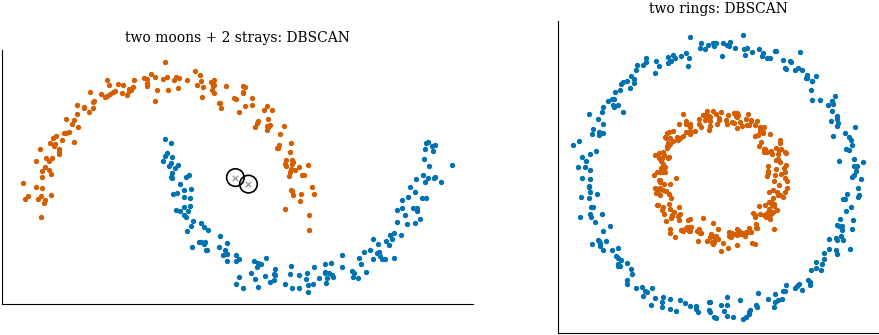

In [5]:
STRAYS = np.array([[0.5, 0.25], [0.6, 0.2]])
Xms = np.vstack([Xm, STRAYS])
db_m = DBSCAN(eps=0.20, min_samples=5).fit_predict(Xms)
db_r = DBSCAN(eps=0.20, min_samples=5).fit_predict(Xr)
print(f"two moons + 2 strays: {n_groups(db_m)} clusters, ARI on the moon points "
      f"{adjusted_rand_score(ym, db_m[:len(ym)]):.2f}; the two strays get the labels {db_m[len(ym):].tolist()} "
      f"(-1 = noise)")
print(f"two rings: {n_groups(db_r)} clusters, {np.sum(db_r == -1)} noise points, ARI {adjusted_rand_score(yr, db_r):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
show_groups(axes[0], Xms, db_m, "two moons + 2 strays: DBSCAN")
axes[0].scatter(*STRAYS.T, s=160, facecolor="none", edgecolor="k", lw=1.2)
show_groups(axes[1], Xr, db_r, "two rings: DBSCAN")
plt.show()

Both shapes found exactly (ARI 1.00, against 0.23 and 0.00 for k-means in &sect;1), and the two stray points
between the moons are called noise (label $-1$). No center, no $K$: just crowds.

## 4. "No $K$ needed" is half true: $\varepsilon$ decides

**Predict first:** on the moons, what happens with a tiny $\varepsilon$? With a huge one?

eps 0.08: 21 clusters,  65 points of noise
eps 0.20:  2 clusters,   0 points of noise
eps 0.30:  1 cluster,   0 points of noise


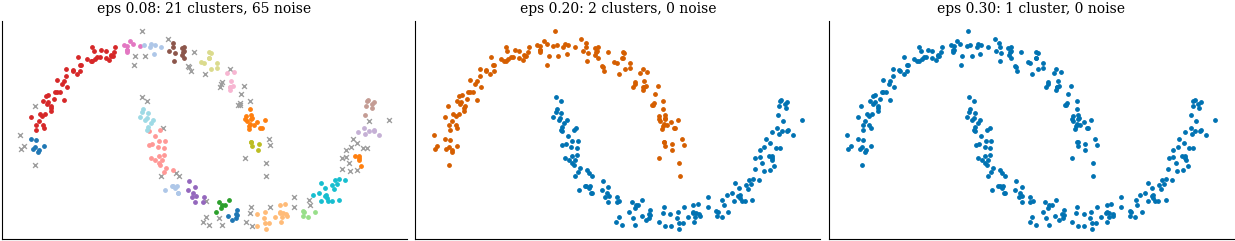


the eps values that give the two moons (ARI above 0.96): from 0.12 to 0.27
at eps 0.12, 93.7% of the points are core; the two moons' closest points are 0.278 apart


10 fresh draws: the window starts between 0.12 and 0.15 and ends between 0.22 and 0.39; every eps from 0.15 to 0.22 works on all 10


In [6]:
def moon_window(X, y):
    "the eps values from 0.05 to 0.39 (step 0.01) at which DBSCAN finds the two moons (ARI above 0.96)"
    good = []
    for eps in np.round(np.arange(0.05, 0.40, 0.01), 2):
        lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
        if n_groups(lab) == 2 and adjusted_rand_score(y, lab) > 0.96:
            good.append(eps)
    return good


fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.2))
for ax, eps in zip(axes, (0.08, 0.20, 0.30)):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm)
    print(f"eps {eps:.2f}: {n_groups(lab):2d} cluster{'s' if n_groups(lab) != 1 else ''}, "
          f"{np.sum(lab == -1):3d} points of noise")
    show_groups(ax, Xm, lab, f"eps {eps:.2f}: {n_groups(lab)} cluster{'s' if n_groups(lab) != 1 else ''}, "
                             f"{np.sum(lab == -1)} noise", s=6)
plt.show()

window = moon_window(Xm, ym)
print(f"\nthe eps values that give the two moons (ARI above 0.96): from {min(window):.2f} to {max(window):.2f}")
core_share = len(DBSCAN(eps=0.12, min_samples=5).fit(Xm).core_sample_indices_) / len(Xm)
gap = np.sqrt(((Xm[ym == 0][:, None] - Xm[ym == 1][None]) ** 2).sum(axis=2)).min()
print(f"at eps 0.12, {core_share:.1%} of the points are core; the two moons' closest points are {gap:.3f} apart")

lows, highs = [], []
for seed in range(1, 11):                             # 10 fresh draws of the moons
    X, y = make_moons(n_samples=300, noise=0.06, random_state=seed)
    ok = moon_window(X, y)
    lows.append(min(ok)); highs.append(max(ok))
print(f"10 fresh draws: the window starts between {min(lows):.2f} and {max(lows):.2f} and ends between "
      f"{min(highs):.2f} and {max(highs):.2f}; every eps from {max(lows):.2f} to {min(highs):.2f} works on all 10")

Too small (0.08): 21 little clusters and 65 points of noise. Too large (0.30): everything in one cluster. In
between, any $\varepsilon$ from 0.12 to 0.27 gives the two moons: trust an answer that survives a wide range of
$\varepsilon$. On 10 fresh draws of the moons the window moves, but every $\varepsilon$ from 0.15 to 0.22 works
on all of them.

A good $\varepsilon$ makes nearly every point a core point (93.7% of the points at 0.12), yet stays below the gap
between clusters (the moons' closest points are 0.278 apart). A tight cluster beside a loose one may need two
different $\varepsilon$, and DBSCAN has only one. So DBSCAN trades choosing $K$ for choosing $\varepsilon$.

## 5. Check yourself: turn the knobs

Back to the ten points. (a) $\varepsilon = 4$: compare the squared distances with 16 instead of 10.24. P4 and P6
are 13 apart (squared). What happens? (b) minPts = 2, with $\varepsilon$ back at 3.2: what happens to P1 and P2?

In [7]:
for eps, min_pts in ((4.0, 3), (3.2, 2)):
    lab, _ = dbscan_by_hand(X10, eps, min_pts, show=False)
    groups = [[NAMES[i] for i in np.flatnonzero(lab == k)] for k in range(n_groups(lab))]
    same = adjusted_rand_score(lab, DBSCAN(eps=eps, min_samples=min_pts).fit_predict(X10)) == 1.0
    print(f"eps {eps:g}, minPts {min_pts}: {len(groups)} cluster{'s' if len(groups) != 1 else ''} {groups}; noise "
          f"{[NAMES[i] for i in np.flatnonzero(lab == -1)]}; same as scikit-learn: {same}")

eps 4, minPts 3: 1 cluster [['P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10']]; noise ['P1', 'P2']; same as scikit-learn: True
eps 3.2, minPts 2: 3 clusters [['P1', 'P2'], ['P3', 'P6', 'P7'], ['P4', 'P5', 'P8', 'P9', 'P10']]; noise []; same as scikit-learn: True


**(a)** P4 and P6 become neighbors (13 is below 16), both are core, so the two clusters join into one; P1 and P2
stay noise. **(b)** A pair is now a crowd: P1 and P2 form a third cluster, and nothing is noise.

**Use DBSCAN when** the groups have odd shapes, or there are outliers to set aside, with few features and one
density.

## 6. Merge the closest, then cut the tree

Hierarchical clustering builds **every** grouping at once. Start with every point as its own group; then
repeat: **merge the two closest groups**. Here the distance between two groups is the gap between their closest
members. The record of the merges is a tree (a **dendrogram**); cutting it at a height gives a grouping. By
hand, on the eight rents.

merge [2.0] and [3.0] at height 1
merge [2.0, 3.0] and [4.0] at height 1
merge [2.0, 3.0, 4.0] and [5.0] at height 1
merge [10.0] and [11.0] at height 1
merge [10.0, 11.0] and [12.0] at height 1
merge [10.0, 11.0, 12.0] and [13.0] at height 1
merge [2.0, 3.0, 4.0, 5.0] and [10.0, 11.0, 12.0, 13.0] at height 5

scipy's merge heights: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 5.0]; the same as by hand: True
cut at height 0.5: 8 groups
cut at height 3  : 2 groups
cut at height 6  : 1 groups
the four linkages' two groups on these rents are the same: True


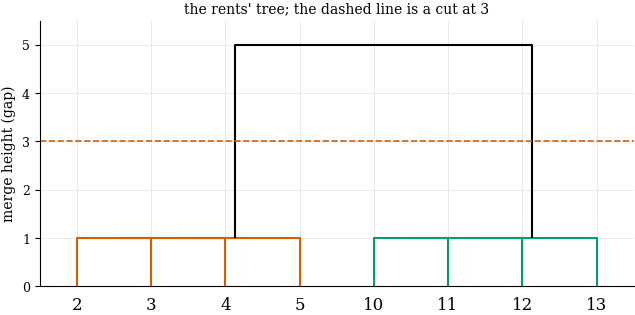

In [8]:
_, rents = make_rent8()
RENTS = sorted(rents.tolist())                       # <-- CHANGE ME: e.g. add a ninth rent, RENTS + [7.5]
groups = [[r] for r in RENTS]
heights = []
while len(groups) > 1:
    best = None
    for i, j in itertools.combinations(range(len(groups)), 2):        # every pair of groups
        gap = min(abs(a - b) for a in groups[i] for b in groups[j])   # single linkage: their closest members
        if best is None or gap < best[0]:
            best = (gap, i, j)                                         # the closest pair so far
    gap, i, j = best
    print(f"merge {groups[i]} and {groups[j]} at height {gap:g}")
    heights.append(gap)
    groups[i] = groups[i] + groups[j]
    del groups[j]

Z = linkage(np.array(RENTS)[:, None], method="single", optimal_ordering=True)   # the same with scipy
print(f"\nscipy's merge heights: {Z[:, 2].tolist()}; the same as by hand: {np.allclose(sorted(heights), Z[:, 2])}")
for h in (0.5, 3, 6):
    print(f"cut at height {h:<3g}: {len(set(fcluster(Z, t=h, criterion='distance')))} groups")
two = {m: AgglomerativeClustering(n_clusters=2, linkage=m).fit_predict(np.array(RENTS)[:, None])
       for m in ("single", "complete", "average", "ward")}
print("the four linkages' two groups on these rents are the same:",
      all(adjusted_rand_score(two["single"], lab) == 1.0 for lab in two.values()))

fig, ax = plt.subplots(figsize=(6.4, 3.2))
dendrogram(Z, labels=[f"{r:g}" for r in RENTS], ax=ax, color_threshold=3, above_threshold_color="k")
ax.axhline(3, color=C1, ls="--", lw=1.2)
ax.set_ylim(0, 1.1 * max(3, Z[:, 2].max()))          # keep the cut at 3 in view
ax.set_ylabel("merge height (gap)"); ax.set_title("the rents' tree; the dashed line is a cut at 3", fontsize=10)
plt.show()

Six merges across gaps of 1, then the gap of 5: on the rents the tree has only three levels (below 1: 8 groups;
between 1 and 5: two groups, {2, 3, 4, 5} and {10, 11, 12, 13}; above 5: one). Like a family tree read upward:
siblings first, then cousins, then the whole family.

**How far apart are two groups? The linkage.** What we just did is **single** linkage: the closest pair.
**Complete**: the farthest pair. **Average**: all the pairs. **Ward**: merge the two groups whose union raises
the cost (the k-means cost) the least, the k-means idea built bottom-up. On the rents all four give the same two
groups. On harder shapes they do not.

## 7. The linkage changes the answer

The cell runs the four linkages on the moons, and ends with one more idea, **spectral clustering**: link each
point to its close neighbors, then cut the graph where the links are fewest and weakest. A link is strong between
close points and fades with distance; `GAMMA` sets how fast: a large `gamma` links only very close points, a
small one links almost everything to everything.

**Predict first:** on the two moons, which rule can follow a crescent?

single   linkage on the moons: ARI 1.00
average  linkage on the moons: ARI 0.43
ward     linkage on the moons: ARI 0.30
complete linkage on the moons: ARI 0.20

single linkage, moons + 2 strays: groups of [300, 2], ARI on the moon points 0.00
its last two merges: at 0.278 (a group of 300 points: both moons) and at 0.314 (the two strays join everything)


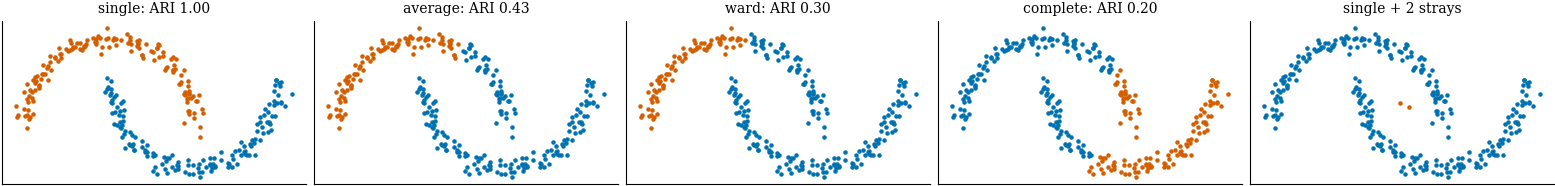


10 fresh draws: single 1.00 to 1.00; average 0.20 to 0.42; ward 0.14 to 0.66; complete 0.22 to 0.47

spectral clustering, gamma 50: ARI 1.00
spectral clustering, gamma 1: ARI 0.29


In [9]:
fig, axes = plt.subplots(1, 5, figsize=(15.6, 3.0))
for ax, m in zip(axes, ("single", "average", "ward", "complete")):
    lab = AgglomerativeClustering(n_clusters=2, linkage=m).fit_predict(Xm)
    print(f"{m:8s} linkage on the moons: ARI {adjusted_rand_score(ym, lab):.2f}")
    show_groups(ax, Xm, lab, f"{m}: ARI {adjusted_rand_score(ym, lab):.2f}", s=5)

lab_s = AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(Xms)    # + the two strays
print(f"\nsingle linkage, moons + 2 strays: groups of {sorted(np.bincount(lab_s).tolist(), reverse=True)}, "
      f"ARI on the moon points {ari(ym, lab_s[:len(ym)]):.2f}")
Zs = linkage(Xms, method="single")
print(f"its last two merges: at {Zs[-2, 2]:.3f} (a group of {Zs[-2, 3]:.0f} points: both moons) and at "
      f"{Zs[-1, 2]:.3f} (the two strays join everything)")
show_groups(axes[4], Xms, lab_s, "single + 2 strays", s=5)
plt.show()

spread = {m: [] for m in ("single", "average", "ward", "complete")}
for seed in range(1, 11):                             # 10 fresh draws of the moons
    X, y = make_moons(n_samples=300, noise=0.06, random_state=seed)
    for m in spread:
        spread[m].append(adjusted_rand_score(y, AgglomerativeClustering(n_clusters=2, linkage=m).fit_predict(X)))
print("\n10 fresh draws:", "; ".join(f"{m} {min(v):.2f} to {max(v):.2f}" for m, v in spread.items()))

GAMMA = 50.0                                          # <-- CHANGE ME: larger = only very close points are linked
print()
for g in (GAMMA, 1.0):                                # a "Graph is not fully connected" warning: gamma is too large
    lab = SpectralClustering(n_clusters=2, affinity="rbf", gamma=g, random_state=0).fit_predict(Xm)
    print(f"spectral clustering, gamma {g:g}: ARI {adjusted_rand_score(ym, lab):.2f}")

Single linkage follows the moons (ARI 1.00): it chains close neighbors. On this draw average linkage scores
0.43, Ward 0.30 and complete 0.20 (k-means: 0.23). Over 10 fresh draws only single linkage is reliable (1.00
every time); the other three move around (average 0.20 to 0.42, Ward 0.14 to 0.66, complete 0.22 to 0.47),
so their order here is luck.

But it is fragile: for two groups it cuts its **biggest gap**, and two strays farther from the moons than the
moons are apart make a bigger one. The moons join each other at 0.278 (their own gap), the strays join last at
0.314, so the two groups become "both moons" (300 points) against "the two strays" (ARI 0.00). DBSCAN called the
same two points noise.

**Spectral clustering**, the graph of neighbors, follows the moons with `gamma = 50` (ARI 1.00). With
scikit-learn's default (`gamma = 1`) far-away points are linked too, and it scores 0.29, barely better than
k-means (0.23).

## 8. Check yourself: the tree

(a) A ninth apartment rents for 7.5. With single linkage, at what height do the two groups merge now? Cut the tree
at 3: how many groups? (b) Could you build a Ward tree for 100,000 customers?

In [10]:
nine = np.array(sorted(rents.tolist() + [7.5]))[:, None]
Z9 = linkage(nine, method="single")
print(f"(a) merge heights with a ninth rent at 7.5: {Z9[:, 2].tolist()}; a cut at 3 gives "
      f"{len(set(fcluster(Z9, t=3, criterion='distance')))} group(s)")
n = 100_000
pairs = n * (n - 1) // 2
print(f"(b) {n:,} points: {pairs:,} distances, at 8 bytes each {pairs * 8 / 1e9:.1f} GB of memory")

(a) merge heights with a ninth rent at 7.5: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.5, 2.5]; a cut at 3 gives 1 group(s)
(b) 100,000 points: 4,999,950,000 distances, at 8 bytes each 40.0 GB of memory


**(a)** At 2.5: the new rent is 2.5 from both 5 and 10, a stepping stone across the gap, so a cut at 3 gives one
group: single linkage **chains**. **(b)** Hardly: Ward (like complete and average linkage) keeps every pairwise
distance: 100,000 points, about 5 billion distances, 40 GB of memory. Use k-means or DBSCAN (or a sample).

**Use hierarchical clustering when** the data is small (up to a few thousand points) and you want the tree, or
every $K$ at once.

## 9. Which method for which situation? The evidence

Five methods, six situations: four made-up shapes (round blobs, two moons, tilted clouds, small beside big), the
two rings, and the standardized wine. Every method gets its best chance: $K$ = the true number of groups; DBSCAN
gets its **best** $\varepsilon$ out of 1,000 values (minPts 5), chosen with the answer key, which real use never
has, so its column is the most DBSCAN can do with minPts 5. The wine's mixture uses round clouds (&sect;10 shows
why). This cell takes about 15 seconds.

**Predict first:** which method wins each row?

In [11]:
wine = load_wine()
Xw, yw = StandardScaler().fit_transform(wine.data), wine.target
ROWS = {"round blobs": shapes["round blobs"], "two moons": (Xm, ym), "two rings": (Xr, yr),
        "tilted clouds": shapes["tilted clouds"], "small beside big": shapes["small beside big"],
        "wine (13-D)": (Xw, yw)}


def best_dbscan(X, y, n_values=1000):
    '''DBSCAN's best ARI over eps values from 0 to the median distance between two points (minPts 5).
    Once every point is in one cluster with no noise, a larger eps cannot change anything: stop there.'''
    best = (-1.0, None, None, None)
    for eps in np.linspace(0, np.median(pdist(X)), n_values + 1)[1:]:
        lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
        score = adjusted_rand_score(y, lab)
        if score > best[0]:
            best = (score, eps, n_groups(lab), int(np.sum(lab == -1)))
        if n_groups(lab) == 1 and np.all(lab == 0):
            break
    return best


print(f"{'':17s}{'k-means':>9s}{'mixture':>9s}{'DBSCAN':>9s}{'Ward':>9s}{'single':>9s}   DBSCAN's best eps")
for name, (X, y) in ROWS.items():
    K = len(np.unique(y))
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X)
    cov = "spherical" if name.startswith("wine") else "full"
    gm = GaussianMixture(n_components=K, covariance_type=cov, n_init=10, random_state=0).fit_predict(X)
    db, eps, k_db, noise = best_dbscan(X, y)
    ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
    single = AgglomerativeClustering(n_clusters=K, linkage="single").fit_predict(X)
    scores = [adjusted_rand_score(y, lab) for lab in (km, gm)] + [db] + \
             [adjusted_rand_score(y, lab) for lab in (ward, single)]
    print(f"{name:17s}" + "".join(f"{(0.0 if abs(s) < 0.005 else s):9.2f}" for s in scores) +
          f"   {eps:.3f} ({k_db} clusters, {noise} noise)")
    if name.startswith("wine"):
        wine_single = sorted(np.bincount(single).tolist(), reverse=True)
print(f"\nwine, single linkage's group sizes: {wine_single}")

                   k-means  mixture   DBSCAN     Ward   single   DBSCAN's best eps


round blobs           1.00     1.00     1.00     1.00     1.00   1.761 (4 clusters, 0 noise)


two moons             0.23     0.46     1.00     0.30     1.00   0.179 (2 clusters, 0 noise)


two rings             0.00     0.00     1.00     0.00     1.00   0.114 (2 clusters, 0 noise)


tilted clouds         0.36     0.81     0.46     0.31     0.00   0.370 (5 clusters, 89 noise)


small beside big      0.21     1.00     0.82     0.24    -0.02   1.366 (2 clusters, 6 noise)


wine (13-D)           0.90     0.88     0.44     0.79    -0.01   2.402 (2 clusters, 34 noise)

wine, single linkage's group sizes: [174, 3, 1]


**No column wins every row.** Round blobs: everybody wins. Moons and rings: the crowd methods (DBSCAN, single
linkage). Tilted clouds and small beside big: the mixture. The wine (13 measurements, standardized): k-means
0.90, the mixture 0.88 and Ward 0.79, while single linkage puts 174 of the 178 wines in one group and DBSCAN,
even at its best, finds two crowds, not three, and calls 34 wines noise. (The tilted clouds' DBSCAN 0.46 needs
an $\varepsilon$ within a hair of 0.370; every cell is one draw of one dataset.)

**Use it when, avoid it when.**

| | use it when | avoid it when | you choose |
|---|---|---|---|
| **k-means** | round groups of similar size; any amount of data | curves, rings, outliers (moons 0.23, rings 0.00); very unequal groups (small beside big 0.21) | $K$ |
| **Gaussian mixture** | stretched, tilted or unequal groups (0.81, 1.00); you need "how sure" | curves and rings (0.46, 0.00); many measurements, few points (full clouds collapse: &sect;10) | $K$, the clouds' shape |
| **DBSCAN** | odd shapes (1.00, 1.00); noise to set aside; few features | many features (the wine: 0.44); groups of different densities | $\varepsilon$, minPts |
| **hierarchical** | small data; you want the tree, or every $K$ | big data (every pair of points is compared); single linkage chains (the wine's 174 of 178) | the linkage, where to cut |

All four measure distances, so features in different units must be **standardized** first. Every one of them has
a knob that decides how many groups you get, so their groups never prove that real groups exist.

**Which one should I use?**

1. First: features in different units? **Standardize** them (the same unit with meaningful spreads, like four
   lengths in cm: keep them).
2. Few features (you can plot them), and curved shapes or outliers to set aside? **DBSCAN**.
3. Otherwise, stretched or unequal groups, or you need "how sure"? A **Gaussian mixture**.
4. Otherwise: **k-means**, with `n_init=10`.
5. On the side: small data, and you want the tree or every $K$? **Hierarchical** clustering (Ward).
6. Then **look** at the groups: do they make sense for what you need?

## 10. In practice: the knobs that matter, and the code

The code you would write, on the wine. Every method is used the same way: `fit_predict` gives one group per row
(DBSCAN's $-1$ = noise). Only `GaussianMixture` lives in `sklearn.mixture`, and it has no `labels_`: use
`predict` or `fit_predict`. The cell also shows why the wine's mixture used round clouds: with many measurements
and few points, **full** clouds can collapse onto a handful of points.

In [12]:
Xs = StandardScaler().fit_transform(wine.data)       # first, because the units differ
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xs)
print(f"KMeans: groups {np.bincount(km.labels_).tolist()}, cost (inertia_) {km.inertia_:.1f}, "
      f"ARI {adjusted_rand_score(wine.target, km.labels_):.2f}")
others = {"GaussianMixture(3, round clouds)": GaussianMixture(n_components=3, covariance_type="spherical",
                                                               n_init=10, random_state=0),
          "AgglomerativeClustering(3, ward)": AgglomerativeClustering(n_clusters=3, linkage="ward"),
          "DBSCAN() with its defaults": DBSCAN()}
for name, model in others.items():
    labels = model.fit_predict(Xs)
    print(f"{name:33s}: {n_groups(labels)} clusters, {np.sum(labels == -1)} noise, "
          f"ARI {adjusted_rand_score(wine.target, labels):.2f}")

COV = "full"                                         # <-- CHANGE ME: "full", "diag", "spherical" or "tied"
fits = [GaussianMixture(n_components=3, covariance_type=COV, n_init=10, random_state=s).fit(Xs) for s in range(20)]
scores = [adjusted_rand_score(wine.target, g.predict(Xs)) for g in fits]
best = max(fits, key=lambda g: g.lower_bound_)       # lower_bound_: each model's fit (log-likelihood per wine)
print(f"\nwines per variety: {np.bincount(wine.target).tolist()}; a full cloud in 13-D has 13 + 13*14/2 = "
      f"{13 + 13 * 14 // 2} numbers to estimate")
print(f"GaussianMixture({COV}) over 20 seeds: ARI from {min(scores):.2f} to {max(scores):.2f}; the fit with the "
      f"highest likelihood has groups of {sorted(np.bincount(best.predict(Xs)).tolist())}, "
      f"ARI {adjusted_rand_score(wine.target, best.predict(Xs)):.2f}")

KMeans: groups [65, 51, 62], cost (inertia_) 1277.9, ARI 0.90
GaussianMixture(3, round clouds) : 3 clusters, 0 noise, ARI 0.88
AgglomerativeClustering(3, ward) : 3 clusters, 0 noise, ARI 0.79
DBSCAN() with its defaults       : 0 clusters, 178 noise, ARI 0.00



wines per variety: [59, 71, 48]; a full cloud in 13-D has 13 + 13*14/2 = 104 numbers to estimate
GaussianMixture(full) over 20 seeds: ARI from 0.44 to 0.88; the fit with the highest likelihood has groups of [3, 54, 121], ARI 0.44


k-means on the standardized wine: ARI 0.90; round clouds 0.88; Ward 0.79. DBSCAN with its defaults
($\varepsilon = 0.5$) calls **every** wine noise: in 13 dimensions the wines are farther apart than that, so tune
$\varepsilon$. And full clouds: over 20 seeds the ARI runs from 0.44 to 0.88, and the fit the mixture likes best
(the highest likelihood) has one cloud of only 3 wines (ARI 0.44). With 13 measurements a full cloud has 104
numbers to estimate from 48 to 71 wines; round clouds have far fewer, and give the same answer on every seed
(set `COV = "spherical"` and run the cell again).

## Recap & exercises

**Recap: the cheat sheet.**

| | the idea | knobs | watch out |
|---|---|---|---|
| **k-means** (round, similar groups) | join the nearest center, move it to the average, repeat | $K$, `n_init` | bad starts; units; it always returns $K$ groups |
| **mixture** (stretched or unequal groups) | clouds with a center, spread, tilt and size; soft memberships (EM) | $K$, `n_init`, the clouds' shape | bad starts; curved shapes |
| **DBSCAN** (any shape, with noise) | clusters are crowded regions; the rest is noise | $\varepsilon$, minPts | many features; different densities |
| **hierarchical** (small data, the whole tree) | merge the closest groups, record a tree, cut it | the linkage, the cut | big data; single linkage chains |

**Close inside, far apart**, measured with a distance, so mind the units. Every method proposes groups; deciding
whether they are useful is your job.

**Exercises.**

1. In &sect;2, set `EPS, MIN_PTS = 3.2, 4` in the first cell and predict the clusters from its table before you
   run the second cell. Then try `EPS, MIN_PTS = 5.5, 3` and read the new table: which pairs became neighbors,
   and which points are noise now?
2. In &sect;6, set `RENTS = sorted(rents.tolist() + [7.5])` and change `min(abs(a - b) ...)` to
   `max(abs(a - b) ...)`: two groups are now as far apart as their farthest members (complete linkage). Where
   does 7.5 join, and how many groups does a cut at 4 give? Compare with single linkage in &sect;8, and check your
   heights with `linkage(np.array(RENTS)[:, None], method="complete")`.
3. In &sect;7, set `GAMMA` to 10, 20 and 100. Where does spectral clustering start to follow the moons?
4. In &sect;9, call `best_dbscan(X, y, n_values=100)` instead of 1,000 values. Which cell changes, and why?
5. **Write it yourself.** Write single linkage for the ten points of &sect;2: groups of point numbers instead of
   rents, and the straight-line distance between two points instead of `abs(a - b)`. Compare your merge heights
   with `linkage(X10, method="single")[:, 2]`.
6. On the standardized wine, loop `min_samples` from 2 to 30 and `eps` from 0.3 to 6. Can DBSCAN find the three
   varieties without calling many wines noise?

**Exit ticket.**

1. k-means repeats two moves: ______ and ______. (A, &sect;2)
2. Two runs of k-means give two different groupings. Why, and what do you do? (A, &sect;5-6)
3. Income in euros, age in years: what do you do before clustering, and why? (A, &sect;9-11)
4. Which method for: (a) crescents with a few outliers; (b) "how sure is each point?"; (c) groups at every level
   of detail? (this notebook, &sect;9)